Crop Yield Prediction Model Comparison:
LinearRegression: MAE=817.49, RMSE=960.62, R2=-1.79
RidgeRegression: MAE=757.65, RMSE=875.88, R2=-1.32
RandomForest: MAE=421.00, RMSE=488.62, R2=0.28


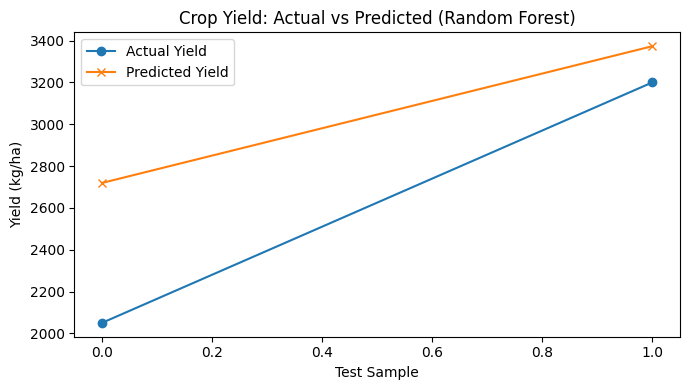

/tmp/ipython-input-3525671569.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_names, y=rf_importances, palette='viridis')


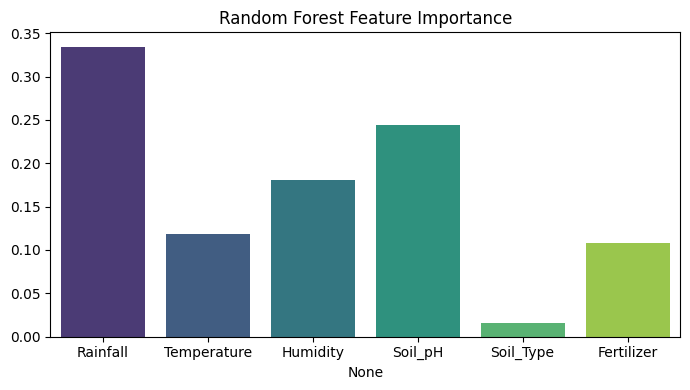


Predicted Crop Yield for input sample: 3547.00 kg/ha


In [1]:
# Crop Yield Prediction Using Regression

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Synthetic Sample Dataset (expand/replace for full runs)
data = pd.DataFrame({
    'Rainfall': [780, 640, 900, 300, 520, 680, 775, 800, 625, 815],
    'Temperature': [22, 19, 24, 30, 27, 21, 23, 20, 26, 22],
    'Humidity': [85, 80, 78, 65, 70, 82, 81, 75, 68, 83],
    'Soil_pH': [6.2, 5.8, 6.6, 7.0, 6.8, 6.0, 5.9, 6.3, 7.2, 6.5],
    'Soil_Type': ['Loamy','Sandy','Clay','Loamy','Sandy','Clay','Loamy','Sandy','Clay','Loamy'],
    'Fertilizer': [1, 1, 2, 3, 2, 1, 1, 2, 3, 1],  # Encoded fertilizer type
    'Crop_Yield': [3400, 3200, 4000, 1800, 2600, 3500, 3300, 4100, 2050, 3700] # kg/ha
})

# Encode categorical variable 'Soil_Type'
data['Soil_Type'] = data['Soil_Type'].map({'Loamy': 0, 'Sandy': 1, 'Clay': 2})

# Features and target
X = data.drop(['Crop_Yield'], axis=1)
y = data['Crop_Yield']

# Preprocessing: scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/Test split for model validation
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Models: Linear Regression, Ridge Regression, Random Forest
models = {
    'LinearRegression': LinearRegression(),
    'RidgeRegression': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    }

# Print metrics table
print("Crop Yield Prediction Model Comparison:")
for name, metrics in results.items():
    print(f"{name}: MAE={metrics['MAE']:.2f}, RMSE={metrics['RMSE']:.2f}, R2={metrics['R2']:.2f}")

# Visualize predictions for best model (Random Forest)
rf_model = models['RandomForest']
y_pred_rf = rf_model.predict(X_test)
plt.figure(figsize=(7,4))
plt.plot(y_test.values, label='Actual Yield', marker='o')
plt.plot(y_pred_rf, label='Predicted Yield', marker='x')
plt.title('Crop Yield: Actual vs Predicted (Random Forest)')
plt.xlabel('Test Sample')
plt.ylabel('Yield (kg/ha)')
plt.legend()
plt.tight_layout()
plt.show()

# Feature Importance for Random Forest
rf_importances = rf_model.feature_importances_
feature_names = X.columns
plt.figure(figsize=(7,4))
sns.barplot(x=feature_names, y=rf_importances, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

# Demo: Predict for new sample data (showing input structure)
new_sample = pd.DataFrame([{
    'Rainfall': 750,
    'Temperature': 21,
    'Humidity': 84,
    'Soil_pH': 6.1,
    'Soil_Type': 0,  # Loamy
    'Fertilizer': 2
}])
new_sample_scaled = scaler.transform(new_sample)
pred_yield = rf_model.predict(new_sample_scaled)[0]
print(f"\nPredicted Crop Yield for input sample: {pred_yield:.2f} kg/ha")
